# **PROJET IA**

Étudiants: SERRATOS Paul 22205053 , CHALOT Maël 22202557



# **Visualisation des données**


On choisit les équipes

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [ ]:
from google.colab import files
cdata_to_load = files.upload() #On importe train_home_team...csv
teamHome = pd.read_csv("train_home_team_statistics_df.csv",sep=",",header=0,index_col=0)
print("TeamHome ok")
data_to_load = files.upload() #On importe train_away_team...csv
teamAway = pd.read_csv("train_away_team_statistics_df.csv",sep=",",header=0,index_col=0)
print("TeamAway ok")
data_to_load = files.upload() #On importe Ytrain.csv
Ytrain = pd.read_csv("Y_train_random.csv",sep=",",header=0,index_col=0)
print("Train ok")

Saving train_home_team_statistics_df.csv to train_home_team_statistics_df.csv
TeamHome ok


Saving train_away_team_statistics_df.csv to train_away_team_statistics_df.csv
TeamAway ok


Saving Y_train_random.csv to Y_train_random.csv
Train ok


On affiche les infos des fichiers importés pour choisir sur quel jeu de données on fera le clustering

In [ ]:
print("TeamHome")
teamHome.info()
teamHome.describe()

TeamHome
<class 'pandas.core.frame.DataFrame'>
Index: 12303 entries, 0 to 12302
Columns: 142 entries, LEAGUE to TEAM_GOALS_5_last_match_std
dtypes: float64(140), object(2)
memory usage: 13.4+ MB


,TEAM_SHOTS_TOTAL_season_sum,TEAM_SHOTS_INSIDEBOX_season_sum,TEAM_SHOTS_OFF_TARGET_season_sum,TEAM_SHOTS_ON_TARGET_season_sum,TEAM_SHOTS_OUTSIDEBOX_season_sum,TEAM_PASSES_season_sum,TEAM_SUCCESSFUL_PASSES_season_sum,TEAM_SAVES_season_sum,TEAM_CORNERS_season_sum,TEAM_FOULS_season_sum,...,TEAM_YELLOWCARDS_5_last_match_std,TEAM_REDCARDS_5_last_match_std,TEAM_OFFSIDES_5_last_match_std,TEAM_ATTACKS_5_last_match_std,TEAM_PENALTIES_5_last_match_std,TEAM_SUBSTITUTIONS_5_last_match_std,TEAM_BALL_SAFE_5_last_match_std,TEAM_DANGEROUS_ATTACKS_5_last_match_std,TEAM_INJURIES_5_last_match_std,TEAM_GOALS_5_last_match_std
count,12043.000000,10918.000000,12303.000000,12301.000000,10916.000000,10890.000000,10919.000000,11523.000000,12302.000000,11546.000000,...,12302.000000,12240.000000,11297.000000,12303.000000,12290.000000,12212.000000,10508.000000,12303.000000,8985.000000,12301.000000
mean,4.391182,4.299872,4.511339,4.150882,4.524643,4.350597,4.130049,4.674043,4.505284,5.135718,...,3.959437,2.927859,3.590068,3.936276,3.559072,3.303144,3.797868,3.694302,3.865331,3.625559
std,2.871062,2.928012,2.806821,2.861291,2.845130,2.908079,2.900489,2.871876,2.802689,2.839771,...,2.850569,3.834186,2.830877,2.830410,3.673394,3.349802,2.866210,2.778135,2.792247,2.851149
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,3.000000,2.000000,3.000000,...,2.000000,0.000000,1.000000,2.000000,0.000000,0.000000,1.000000,2.000000,2.000000,1.000000
50%,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,5.000000,4.000000,5.000000,...,4.000000,0.000000,3.000000,4.000000,4.000000,3.000000,3.000000,3.000000,3.000000,3.000000
75%,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,7.000000,6.000000,7.000000,...,6.000000,6.000000,5.000000,6.000000,6.000000,6.000000,6.000000,5.000000,6.000000,5.000000
max,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,...,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000


In [ ]:
print("TeamAway")
teamAway.info()
teamAway.describe()

TeamAway
<class 'pandas.core.frame.DataFrame'>
Index: 12303 entries, 0 to 12302
Columns: 142 entries, LEAGUE to TEAM_GOALS_5_last_match_std
dtypes: float64(140), object(2)
memory usage: 13.4+ MB


,TEAM_SHOTS_TOTAL_season_sum,TEAM_SHOTS_INSIDEBOX_season_sum,TEAM_SHOTS_OFF_TARGET_season_sum,TEAM_SHOTS_ON_TARGET_season_sum,TEAM_SHOTS_OUTSIDEBOX_season_sum,TEAM_PASSES_season_sum,TEAM_SUCCESSFUL_PASSES_season_sum,TEAM_SAVES_season_sum,TEAM_CORNERS_season_sum,TEAM_FOULS_season_sum,...,TEAM_YELLOWCARDS_5_last_match_std,TEAM_REDCARDS_5_last_match_std,TEAM_OFFSIDES_5_last_match_std,TEAM_ATTACKS_5_last_match_std,TEAM_PENALTIES_5_last_match_std,TEAM_SUBSTITUTIONS_5_last_match_std,TEAM_BALL_SAFE_5_last_match_std,TEAM_DANGEROUS_ATTACKS_5_last_match_std,TEAM_INJURIES_5_last_match_std,TEAM_GOALS_5_last_match_std
count,12044.000000,10917.000000,12303.000000,12301.000000,10914.000000,10886.000000,10918.000000,11518.000000,12302.000000,11540.000000,...,12302.000000,12240.000000,11298.000000,12303.000000,12290.000000,12212.000000,10467.000000,12303.000000,8990.000000,12301.000000
mean,4.472351,4.377943,4.591238,4.222746,4.585487,4.378100,4.153874,4.608092,4.576329,5.128683,...,3.906438,2.805474,3.600195,3.936032,3.701302,3.271536,3.804911,3.758026,3.886207,3.687342
std,2.885075,2.933934,2.806838,2.874215,2.858025,2.921979,2.914109,2.863557,2.828166,2.844497,...,2.823153,3.774745,2.831322,2.823259,3.696370,3.335124,2.863371,2.814694,2.795961,2.856081
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,3.000000,...,2.000000,0.000000,1.000000,2.000000,0.000000,0.000000,2.000000,2.000000,2.000000,2.000000
50%,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,5.000000,...,4.000000,0.000000,3.000000,4.000000,5.000000,3.000000,3.000000,3.000000,3.000000,3.000000
75%,6.000000,7.000000,7.000000,6.000000,7.000000,6.000000,6.000000,7.000000,7.000000,7.000000,...,6.000000,6.000000,5.000000,6.000000,7.000000,6.000000,6.000000,6.000000,6.000000,6.000000
max,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,...,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000


On charge ces données seulement pour connaître à quoi le modèle de prédiction doit ressembler

In [ ]:
print("Ytrain")
Ytrain.info()
Ytrain.describe()

Ytrain
<class 'pandas.core.frame.DataFrame'>
Index: 12303 entries, 0 to 12302
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   HOME_WINS  12303 non-null  int64
 1   DRAW       12303 non-null  int64
 2   AWAY_WINS  12303 non-null  int64
dtypes: int64(3)
memory usage: 384.5 KB


,HOME_WINS,DRAW,AWAY_WINS
count,12303.000000,12303.000000,12303.000000
mean,0.435341,0.258961,0.305698
std,0.495822,0.438082,0.460721
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000
75%,1.000000,1.000000,1.000000
max,1.000000,1.000000,1.000000


**Rappel**
* **`count`**: Le nombre de valeurs non manquantes pour chaque colonne numérique.
* **`mean`**: La moyenne (valeur centrale) des valeurs numériques dans la colonne.
* **`std`**: L'écart type, qui mesure la dispersion des valeurs autour de la moyenne. Un écart type élevé indique une grande variabilité des données, tandis qu'un faible écart type indique que les valeurs sont regroupées autour de la moyenne.
* **`min`**: La valeur minimale dans la colonne.
* **`25%`**: Le premier quartile (25e percentile).  25 % des valeurs sont inférieures à cette valeur.
* **`50%`**: La médiane (50e percentile).  50 % des valeurs sont inférieures à cette valeur. C'est une autre mesure de la valeur centrale, moins sensible aux valeurs aberrantes que la moyenne.
* **`75%`**: Le troisième quartile (75e percentile).  75 % des valeurs sont inférieures à cette valeur.
* **`max`**: La valeur maximale dans la colonne.

# **Clustering**

### **CLUSTERING AVEC TEAM_HOME (sans rassembler les matchs des équipes)**

On enlève les endroits où il y a des données N/A car ils ne permettent pas de faire le clustering

In [ ]:
# Vérifie la structure
print("Dimensions initiales :", teamHome.shape)
print("Valeurs manquantes restantes au début:", teamHome.isnull().sum().sum())

# Suppression des lignes contenant trop de valeurs manquantes (facultatif mais utile)
team_clean = teamHome.dropna(thresh=100)  # Conserve les lignes avec au moins 100 valeurs non nulles

# Remplissage des NaN restants avec la médiane (pour les colonnes numériques)
team_clean = team_clean.fillna(team_clean.median(numeric_only=True))

# Vérification
print("Dimensions après nettoyage :", team_clean.shape)
print("Valeurs manquantes restantes :", team_clean.isnull().sum().sum())

Dimensions initiales : (12303, 142)
Valeurs manquantes restantes au début: 82407
Dimensions après nettoyage : (11395, 142)
Valeurs manquantes restantes : 0


In [ ]:
# On enlève les colonnes non numériques (LEAGUE, TEAM_NAME)
X = team_clean.drop(columns=["LEAGUE", "TEAM_NAME"])

# Juste pour vérifier
print("Nombre de features utilisées :", X.shape[1])

Nombre de features utilisées : 140


On commence le clustering

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)


# On ajoute le cluster à notre dataframe original
team_clean["CLUSTER"] = clusters

In [ ]:
# Moyenne des statistiques par cluster
cluster_means = team_clean.groupby("CLUSTER").mean(numeric_only=True)

# Affiche pour analyse
pd.set_option("display.max_columns", None)  # Affiche toutes les colonnes
display(cluster_means)

,TEAM_SHOTS_TOTAL_season_sum,TEAM_SHOTS_INSIDEBOX_season_sum,TEAM_SHOTS_OFF_TARGET_season_sum,TEAM_SHOTS_ON_TARGET_season_sum,TEAM_SHOTS_OUTSIDEBOX_season_sum,TEAM_PASSES_season_sum,TEAM_SUCCESSFUL_PASSES_season_sum,TEAM_SAVES_season_sum,TEAM_CORNERS_season_sum,TEAM_FOULS_season_sum,TEAM_YELLOWCARDS_season_sum,TEAM_REDCARDS_season_sum,TEAM_OFFSIDES_season_sum,TEAM_ATTACKS_season_sum,TEAM_PENALTIES_season_sum,TEAM_SUBSTITUTIONS_season_sum,TEAM_BALL_SAFE_season_sum,TEAM_DANGEROUS_ATTACKS_season_sum,TEAM_INJURIES_season_sum,TEAM_GOALS_season_sum,TEAM_GAME_WON_season_sum,TEAM_GAME_DRAW_season_sum,TEAM_GAME_LOST_season_sum,TEAM_SHOTS_TOTAL_season_average,TEAM_SHOTS_INSIDEBOX_season_average,TEAM_SHOTS_OFF_TARGET_season_average,TEAM_SHOTS_ON_TARGET_season_average,TEAM_SHOTS_OUTSIDEBOX_season_average,TEAM_PASSES_season_average,TEAM_SUCCESSFUL_PASSES_season_average,TEAM_SUCCESSFUL_PASSES_PERCENTAGE_season_average,TEAM_SAVES_season_average,TEAM_CORNERS_season_average,TEAM_BALL_POSSESSION_season_average,TEAM_FOULS_season_average,TEAM_YELLOWCARDS_season_average,TEAM_REDCARDS_season_average,TEAM_OFFSIDES_season_average,TEAM_ATTACKS_season_average,TEAM_PENALTIES_season_average,TEAM_SUBSTITUTIONS_season_average,TEAM_BALL_SAFE_season_average,TEAM_DANGEROUS_ATTACKS_season_average,TEAM_INJURIES_season_average,TEAM_GOALS_season_average,TEAM_GAME_WON_season_average,TEAM_GAME_DRAW_season_average,TEAM_GAME_LOST_season_average,TEAM_SHOTS_TOTAL_season_std,TEAM_SHOTS_INSIDEBOX_season_std,TEAM_SHOTS_OFF_TARGET_season_std,TEAM_SHOTS_ON_TARGET_season_std,TEAM_SHOTS_OUTSIDEBOX_season_std,TEAM_PASSES_season_std,TEAM_SUCCESSFUL_PASSES_season_std,TEAM_SUCCESSFUL_PASSES_PERCENTAGE_season_std,TEAM_SAVES_season_std,TEAM_CORNERS_season_std,TEAM_BALL_POSSESSION_season_std,TEAM_FOULS_season_std,TEAM_YELLOWCARDS_season_std,TEAM_REDCARDS_season_std,TEAM_OFFSIDES_season_std,TEAM_ATTACKS_season_std,TEAM_PENALTIES_season_std,TEAM_SUBSTITUTIONS_season_std,TEAM_BALL_SAFE_season_std,TEAM_DANGEROUS_ATTACKS_season_std,TEAM_INJURIES_season_std,TEAM_GOALS_season_std,TEAM_SHOTS_TOTAL_5_last_match_sum,TEAM_SHOTS_INSIDEBOX_5_last_match_sum,TEAM_SHOTS_OFF_TARGET_5_last_match_sum,TEAM_SHOTS_ON_TARGET_5_last_match_sum,TEAM_SHOTS_OUTSIDEBOX_5_last_match_sum,TEAM_PASSES_5_last_match_sum,TEAM_SUCCESSFUL_PASSES_5_last_match_sum,TEAM_SAVES_5_last_match_sum,TEAM_CORNERS_5_last_match_sum,TEAM_FOULS_5_last_match_sum,TEAM_YELLOWCARDS_5_last_match_sum,TEAM_REDCARDS_5_last_match_sum,TEAM_OFFSIDES_5_last_match_sum,TEAM_ATTACKS_5_last_match_sum,TEAM_PENALTIES_5_last_match_sum,TEAM_SUBSTITUTIONS_5_last_match_sum,TEAM_BALL_SAFE_5_last_match_sum,TEAM_DANGEROUS_ATTACKS_5_last_match_sum,TEAM_INJURIES_5_last_match_sum,TEAM_GOALS_5_last_match_sum,TEAM_GAME_WON_5_last_match_sum,TEAM_GAME_DRAW_5_last_match_sum,TEAM_GAME_LOST_5_last_match_sum,TEAM_SHOTS_TOTAL_5_last_match_average,TEAM_SHOTS_INSIDEBOX_5_last_match_average,TEAM_SHOTS_OFF_TARGET_5_last_match_average,TEAM_SHOTS_ON_TARGET_5_last_match_average,TEAM_SHOTS_OUTSIDEBOX_5_last_match_average,TEAM_PASSES_5_last_match_average,TEAM_SUCCESSFUL_PASSES_5_last_match_average,TEAM_SUCCESSFUL_PASSES_PERCENTAGE_5_last_match_average,TEAM_SAVES_5_last_match_average,TEAM_CORNERS_5_last_match_average,TEAM_BALL_POSSESSION_5_last_match_average,TEAM_FOULS_5_last_match_average,TEAM_YELLOWCARDS_5_last_match_average,TEAM_REDCARDS_5_last_match_average,TEAM_OFFSIDES_5_last_match_average,TEAM_ATTACKS_5_last_match_average,TEAM_PENALTIES_5_last_match_average,TEAM_SUBSTITUTIONS_5_last_match_average,TEAM_BALL_SAFE_5_last_match_average,TEAM_DANGEROUS_ATTACKS_5_last_match_average,TEAM_INJURIES_5_last_match_average,TEAM_GOALS_5_last_match_average,TEAM_GAME_WON_5_last_match_average,TEAM_GAME_DRAW_5_last_match_average,TEAM_GAME_LOST_5_last_match_average,TEAM_SHOTS_TOTAL_5_last_match_std,TEAM_SHOTS_INSIDEBOX_5_last_match_std,TEAM_SHOTS_OFF_TARGET_5_last_match_std,TEAM_SHOTS_ON_TARGET_5_last_match_std,TEAM_SHOTS_OUTSIDEBOX_5_last_match_std,TEAM_PASSES_5_last_match_std,TEAM_SUCCESSFUL

Affichage du clustering

[0.20953035 0.0526409 ]


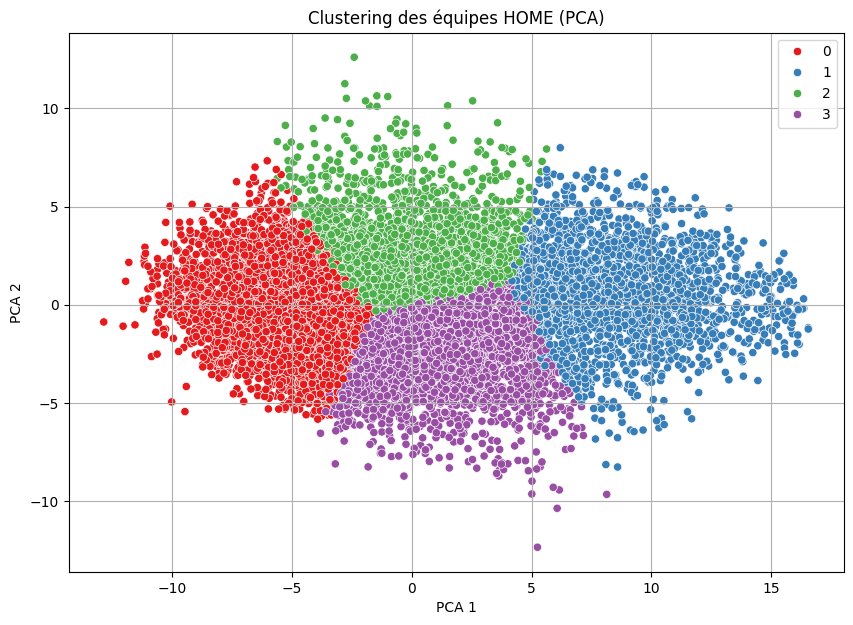

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
# explications PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print(pca.explained_variance_ratio_)

plt.figure(figsize=(10, 7))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=clusters, palette="Set1")
plt.title("Clustering des équipes HOME (PCA)")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.grid(True)
plt.show()

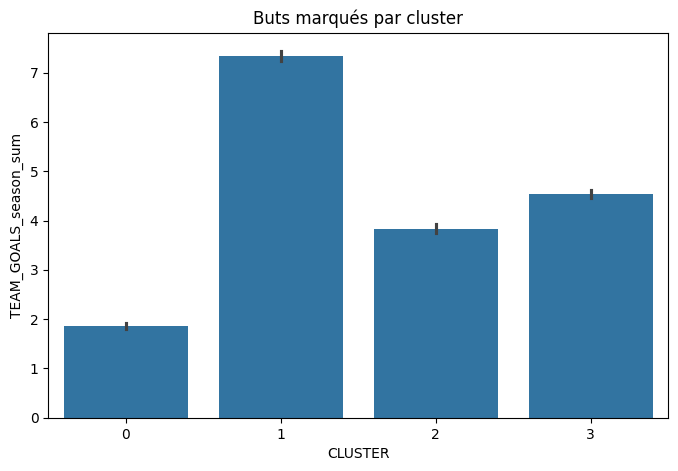

In [ ]:
import matplotlib.pyplot as plt

# On peut visualiser les features par cluster
plt.figure(figsize=(8,5))
sns.barplot(data=team_clean, x="CLUSTER", y="TEAM_GOALS_season_sum")
plt.title("Buts marqués par cluster")
plt.show()

A partir des différents tableaux,on peut commencer à tirer des conclusions. Par exemple, dans le cas ci-dessus on pourrait dire que les équipes du cluster 1 sont les plus offensives

### **CLUSTERING AVEC TEAM_HOME (en rassemblant les matchs des équipes)**

Maintenant on pourrait aussi regrouper les lignes par équipe, vu que chaque ligne représente un match et une équipe a pu jouer plusieurs matchs

In [ ]:
# 1. Regrouper toutes les lignes par équipe
teamHome_grouped = teamHome.groupby("TEAM_NAME").mean(numeric_only=True)

# 2. Nettoyer les colonnes inutiles (par ex. ID)
if "ID" in teamHome_grouped.columns:
    teamHome_grouped = teamHome_grouped.drop(columns=["ID"])

# 3. Supprimer les colonnes avec trop de valeurs manquantes
teamHome_grouped = teamHome_grouped.dropna(thresh=100)

# 4. Remplir les NaN restants avec la médiane
teamHome_grouped = teamHome_grouped.fillna(teamHome_grouped.median())

# 5. Standardisation
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(teamHome_grouped)

# 6. Clustering
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

# 7. Associer chaque équipe à un cluster
team_clusters = pd.DataFrame({"TEAM_NAME": teamHome_grouped.index, "CLUSTER": clusters})

In [ ]:
# 8. Ajouter les clusters au dataframe groupé
teamHome_grouped["CLUSTER"] = clusters

<ipython-input-98-50dfc1b39019>:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  teamHome_grouped["CLUSTER"] = clusters


In [ ]:
# 9. Moyennes des caractéristiques pour chaque cluster
cluster_means = teamHome_grouped.groupby("CLUSTER").mean()
print("Statistiques moyennes par cluster :")
display(cluster_means)

Statistiques moyennes par cluster :


,TEAM_SHOTS_TOTAL_season_sum,TEAM_SHOTS_INSIDEBOX_season_sum,TEAM_SHOTS_OFF_TARGET_season_sum,TEAM_SHOTS_ON_TARGET_season_sum,TEAM_SHOTS_OUTSIDEBOX_season_sum,TEAM_PASSES_season_sum,TEAM_SUCCESSFUL_PASSES_season_sum,TEAM_SAVES_season_sum,TEAM_CORNERS_season_sum,TEAM_FOULS_season_sum,TEAM_YELLOWCARDS_season_sum,TEAM_REDCARDS_season_sum,TEAM_OFFSIDES_season_sum,TEAM_ATTACKS_season_sum,TEAM_PENALTIES_season_sum,TEAM_SUBSTITUTIONS_season_sum,TEAM_BALL_SAFE_season_sum,TEAM_DANGEROUS_ATTACKS_season_sum,TEAM_INJURIES_season_sum,TEAM_GOALS_season_sum,TEAM_GAME_WON_season_sum,TEAM_GAME_DRAW_season_sum,TEAM_GAME_LOST_season_sum,TEAM_SHOTS_TOTAL_season_average,TEAM_SHOTS_INSIDEBOX_season_average,TEAM_SHOTS_OFF_TARGET_season_average,TEAM_SHOTS_ON_TARGET_season_average,TEAM_SHOTS_OUTSIDEBOX_season_average,TEAM_PASSES_season_average,TEAM_SUCCESSFUL_PASSES_season_average,TEAM_SUCCESSFUL_PASSES_PERCENTAGE_season_average,TEAM_SAVES_season_average,TEAM_CORNERS_season_average,TEAM_BALL_POSSESSION_season_average,TEAM_FOULS_season_average,TEAM_YELLOWCARDS_season_average,TEAM_REDCARDS_season_average,TEAM_OFFSIDES_season_average,TEAM_ATTACKS_season_average,TEAM_PENALTIES_season_average,TEAM_SUBSTITUTIONS_season_average,TEAM_BALL_SAFE_season_average,TEAM_DANGEROUS_ATTACKS_season_average,TEAM_INJURIES_season_average,TEAM_GOALS_season_average,TEAM_GAME_WON_season_average,TEAM_GAME_DRAW_season_average,TEAM_GAME_LOST_season_average,TEAM_SHOTS_TOTAL_season_std,TEAM_SHOTS_INSIDEBOX_season_std,TEAM_SHOTS_OFF_TARGET_season_std,TEAM_SHOTS_ON_TARGET_season_std,TEAM_SHOTS_OUTSIDEBOX_season_std,TEAM_PASSES_season_std,TEAM_SUCCESSFUL_PASSES_season_std,TEAM_SUCCESSFUL_PASSES_PERCENTAGE_season_std,TEAM_SAVES_season_std,TEAM_CORNERS_season_std,TEAM_BALL_POSSESSION_season_std,TEAM_FOULS_season_std,TEAM_YELLOWCARDS_season_std,TEAM_REDCARDS_season_std,TEAM_OFFSIDES_season_std,TEAM_ATTACKS_season_std,TEAM_PENALTIES_season_std,TEAM_SUBSTITUTIONS_season_std,TEAM_BALL_SAFE_season_std,TEAM_DANGEROUS_ATTACKS_season_std,TEAM_INJURIES_season_std,TEAM_GOALS_season_std,TEAM_SHOTS_TOTAL_5_last_match_sum,TEAM_SHOTS_INSIDEBOX_5_last_match_sum,TEAM_SHOTS_OFF_TARGET_5_last_match_sum,TEAM_SHOTS_ON_TARGET_5_last_match_sum,TEAM_SHOTS_OUTSIDEBOX_5_last_match_sum,TEAM_PASSES_5_last_match_sum,TEAM_SUCCESSFUL_PASSES_5_last_match_sum,TEAM_SAVES_5_last_match_sum,TEAM_CORNERS_5_last_match_sum,TEAM_FOULS_5_last_match_sum,TEAM_YELLOWCARDS_5_last_match_sum,TEAM_REDCARDS_5_last_match_sum,TEAM_OFFSIDES_5_last_match_sum,TEAM_ATTACKS_5_last_match_sum,TEAM_PENALTIES_5_last_match_sum,TEAM_SUBSTITUTIONS_5_last_match_sum,TEAM_BALL_SAFE_5_last_match_sum,TEAM_DANGEROUS_ATTACKS_5_last_match_sum,TEAM_INJURIES_5_last_match_sum,TEAM_GOALS_5_last_match_sum,TEAM_GAME_WON_5_last_match_sum,TEAM_GAME_DRAW_5_last_match_sum,TEAM_GAME_LOST_5_last_match_sum,TEAM_SHOTS_TOTAL_5_last_match_average,TEAM_SHOTS_INSIDEBOX_5_last_match_average,TEAM_SHOTS_OFF_TARGET_5_last_match_average,TEAM_SHOTS_ON_TARGET_5_last_match_average,TEAM_SHOTS_OUTSIDEBOX_5_last_match_average,TEAM_PASSES_5_last_match_average,TEAM_SUCCESSFUL_PASSES_5_last_match_average,TEAM_SUCCESSFUL_PASSES_PERCENTAGE_5_last_match_average,TEAM_SAVES_5_last_match_average,TEAM_CORNERS_5_last_match_average,TEAM_BALL_POSSESSION_5_last_match_average,TEAM_FOULS_5_last_match_average,TEAM_YELLOWCARDS_5_last_match_average,TEAM_REDCARDS_5_last_match_average,TEAM_OFFSIDES_5_last_match_average,TEAM_ATTACKS_5_last_match_average,TEAM_PENALTIES_5_last_match_average,TEAM_SUBSTITUTIONS_5_last_match_average,TEAM_BALL_SAFE_5_last_match_average,TEAM_DANGEROUS_ATTACKS_5_last_match_average,TEAM_INJURIES_5_last_match_average,TEAM_GOALS_5_last_match_average,TEAM_GAME_WON_5_last_match_average,TEAM_GAME_DRAW_5_last_match_average,TEAM_GAME_LOST_5_last_match_average,TEAM_SHOTS_TOTAL_5_last_match_std,TEAM_SHOTS_INSIDEBOX_5_last_match_std,TEAM_SHOTS_OFF_TARGET_5_last_match_std,TEAM_SHOTS_ON_TARGET_5_last_match_std,TEAM_SHOTS_OUTSIDEBOX_5_last_match_std,TEAM_PASSES_5_last_match_std,TEAM_SUCCESSFUL

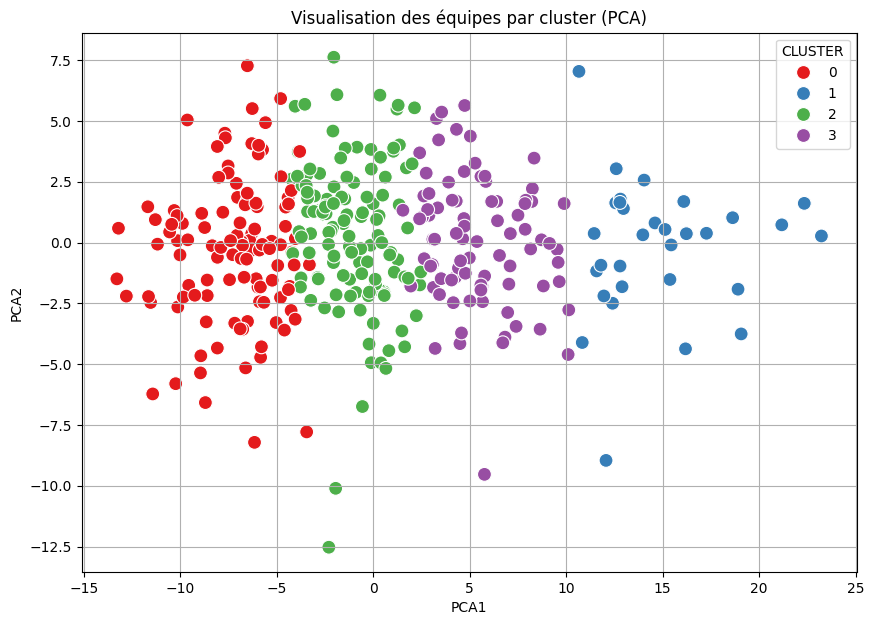

In [ ]:
# 10. Affichage
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# PCA pour réduire les dimensions pour visualiser
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Créer un DataFrame pour le graphe
pca_df = pd.DataFrame({
    "PCA1": X_pca[:, 0],
    "PCA2": X_pca[:, 1],
    "CLUSTER": clusters,
    "TEAM_NAME": teamHome_grouped.index
})

# Tracer les clusters
plt.figure(figsize=(10, 7))
sns.scatterplot(data=pca_df, x="PCA1", y="PCA2", hue="CLUSTER", palette="Set1", s=100)
#for i in range(pca_df.shape[0]):
#    plt.text(pca_df["PCA1"][i]+0.02, pca_df["PCA2"][i], pca_df["TEAM_NAME"][i], fontsize=9)
plt.title("Visualisation des équipes par cluster (PCA)")
plt.grid(True)
plt.show()

# La partie du code commenté c'est pour afficher les noms des équipes mais c'est un peu illisisble

In [ ]:
# 11. Voir quelles équipes sont dans quel cluster
for c in sorted(teamHome_grouped["CLUSTER"].unique()):
    print(f"\nCluster {c} :")
    print(teamHome_grouped[teamHome_grouped["CLUSTER"] == c].index.tolist())


Cluster 0 :
['ADO Den Haag', 'AFC Bournemouth', 'AFC Wimbledon', 'AS Eupen', 'Aldosivi', 'Amiens SC', 'América Mineiro', 'Belenenses', 'Belgrano', 'Benevento', 'Boavista', 'Brescia', 'Burnley', 'Béziers', 'CSA', 'Caen', 'Cagliari', 'Cercle Brugge', 'Chambly', 'Chapecoense', 'Chaves', 'Chievo', 'Coritiba', 'Crotone', 'Crystal Palace', 'Cádiz', 'DSC Arminia Bielefeld', 'De Graafschap', 'Deportivo Alavés', 'Desportivo Aves', 'Dijon', 'Dunkerque', 'Elche', 'Esbjerg', 'Everton', 'Excelsior', 'FC Augsburg', 'FC Groningen', 'FC Köln', 'FC Twente', 'FC Union Berlin', 'Farense', 'Feirense', 'Fortaleza', 'Fortuna Düsseldorf', 'Fortuna Sittard', 'Frosinone', 'Fulham', 'Genoa', 'Getafe', 'Girona', 'Godoy Cruz', 'Goiás', 'Granada', 'Grimsby Town', 'Hannover 96', 'Hellas Verona', 'Hertha BSC', 'Hobro', 'Horsens', 'Huracán', 'Lecce', 'Leganés', 'Lokeren', 'Lyngby', 'Macclesfield Town', 'Mallorca', 'Marítimo', 'Matsumoto Yamaga', 'Moreirense', 'NAC Breda', 'Newcastle United', 'Norwich City', 'Nürnber

### **CLUSTERING AVEC TEAM_AWAY**

*(On peut faire la même chose avec les données de team_away)*

On enlève les endroits où il y a des données N/A car ils ne permettent pas de faire le clustering

In [ ]:
# Vérifie la structure
print("Dimensions initiales :", teamAway.shape)

print("Valeurs manquantes restantes au début:", teamAway.isnull().sum().sum())

# Suppression des lignes contenant trop de valeurs manquantes (facultatif mais utile)
team_clean = teamAway.dropna(thresh=100)  # Conserve les lignes avec au moins 100 valeurs non nulles

# Remplissage des NaN restants avec la médiane (pour les colonnes numériques)
team_clean = team_clean.fillna(team_clean.median(numeric_only=True))

# Vérification
print("Dimensions après nettoyage :", team_clean.shape)
print("Valeurs manquantes restantes :", team_clean.isnull().sum().sum())

Dimensions initiales : (12303, 142)
Valeurs manquantes restantes au début: 82495
Dimensions après nettoyage : (11394, 142)
Valeurs manquantes restantes : 0


In [ ]:
# On enlève les colonnes non numériques (LEAGUE, TEAM_NAME)
X = team_clean.drop(columns=["LEAGUE", "TEAM_NAME"])

# Juste pour vérifier
print("Nombre de features utilisées :", X.shape[1])

Nombre de features utilisées : 140


On commence le clustering

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

# On ajoute le cluster à notre dataframe original
team_clean["CLUSTER"] = clusters

<ipython-input-105-5b8c049a2900>:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  team_clean["CLUSTER"] = clusters


Affichage du clustering

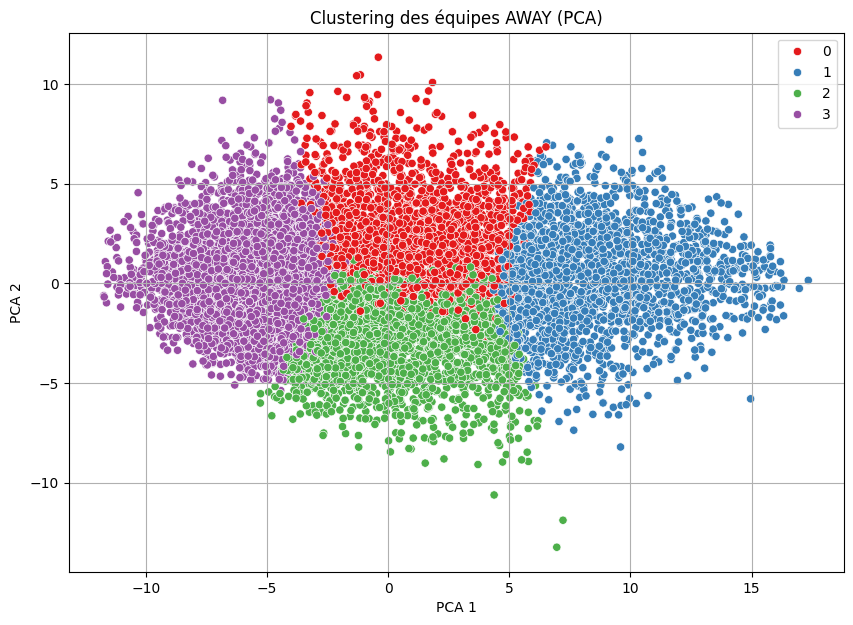

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 7))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=clusters, palette="Set1")
plt.title("Clustering des équipes AWAY (PCA)")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.grid(True)
plt.show()

In [ ]:
# 1. Regrouper toutes les lignes par équipe
teamAway_grouped = teamAway.groupby("TEAM_NAME").mean(numeric_only=True)

# 2. Nettoyer les colonnes inutiles (par ex. ID)
if "ID" in teamAway_grouped.columns:
    teamAway_grouped = teamAway_grouped.drop(columns=["ID"])

# 3. Supprimer les colonnes avec trop de valeurs manquantes
teamAway_grouped = teamAway_grouped.dropna(thresh=100)

# 4. Remplir les NaN restants avec la médiane
teamAway_grouped = teamAway_grouped.fillna(teamAway_grouped.median())

# 5. Standardisation
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(teamAway_grouped)

# 6. Clustering
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

# 7. Associer chaque équipe à un cluster
team_clusters = pd.DataFrame({
    "TEAM_NAME": teamAway_grouped.index,
    "CLUSTER": clusters
})

In [ ]:
# 8. Ajouter les clusters au dataframe groupé
teamAway_grouped["CLUSTER"] = clusters

<ipython-input-108-025b63a4c270>:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  teamAway_grouped["CLUSTER"] = clusters


In [ ]:
# 9. Moyennes des caractéristiques pour chaque cluster
cluster_means = teamAway_grouped.groupby("CLUSTER").mean()
print("Statistiques moyennes par cluster :")
display(cluster_means)

Statistiques moyennes par cluster :


,TEAM_SHOTS_TOTAL_season_sum,TEAM_SHOTS_INSIDEBOX_season_sum,TEAM_SHOTS_OFF_TARGET_season_sum,TEAM_SHOTS_ON_TARGET_season_sum,TEAM_SHOTS_OUTSIDEBOX_season_sum,TEAM_PASSES_season_sum,TEAM_SUCCESSFUL_PASSES_season_sum,TEAM_SAVES_season_sum,TEAM_CORNERS_season_sum,TEAM_FOULS_season_sum,TEAM_YELLOWCARDS_season_sum,TEAM_REDCARDS_season_sum,TEAM_OFFSIDES_season_sum,TEAM_ATTACKS_season_sum,TEAM_PENALTIES_season_sum,TEAM_SUBSTITUTIONS_season_sum,TEAM_BALL_SAFE_season_sum,TEAM_DANGEROUS_ATTACKS_season_sum,TEAM_INJURIES_season_sum,TEAM_GOALS_season_sum,TEAM_GAME_WON_season_sum,TEAM_GAME_DRAW_season_sum,TEAM_GAME_LOST_season_sum,TEAM_SHOTS_TOTAL_season_average,TEAM_SHOTS_INSIDEBOX_season_average,TEAM_SHOTS_OFF_TARGET_season_average,TEAM_SHOTS_ON_TARGET_season_average,TEAM_SHOTS_OUTSIDEBOX_season_average,TEAM_PASSES_season_average,TEAM_SUCCESSFUL_PASSES_season_average,TEAM_SUCCESSFUL_PASSES_PERCENTAGE_season_average,TEAM_SAVES_season_average,TEAM_CORNERS_season_average,TEAM_BALL_POSSESSION_season_average,TEAM_FOULS_season_average,TEAM_YELLOWCARDS_season_average,TEAM_REDCARDS_season_average,TEAM_OFFSIDES_season_average,TEAM_ATTACKS_season_average,TEAM_PENALTIES_season_average,TEAM_SUBSTITUTIONS_season_average,TEAM_BALL_SAFE_season_average,TEAM_DANGEROUS_ATTACKS_season_average,TEAM_INJURIES_season_average,TEAM_GOALS_season_average,TEAM_GAME_WON_season_average,TEAM_GAME_DRAW_season_average,TEAM_GAME_LOST_season_average,TEAM_SHOTS_TOTAL_season_std,TEAM_SHOTS_INSIDEBOX_season_std,TEAM_SHOTS_OFF_TARGET_season_std,TEAM_SHOTS_ON_TARGET_season_std,TEAM_SHOTS_OUTSIDEBOX_season_std,TEAM_PASSES_season_std,TEAM_SUCCESSFUL_PASSES_season_std,TEAM_SUCCESSFUL_PASSES_PERCENTAGE_season_std,TEAM_SAVES_season_std,TEAM_CORNERS_season_std,TEAM_BALL_POSSESSION_season_std,TEAM_FOULS_season_std,TEAM_YELLOWCARDS_season_std,TEAM_REDCARDS_season_std,TEAM_OFFSIDES_season_std,TEAM_ATTACKS_season_std,TEAM_PENALTIES_season_std,TEAM_SUBSTITUTIONS_season_std,TEAM_BALL_SAFE_season_std,TEAM_DANGEROUS_ATTACKS_season_std,TEAM_INJURIES_season_std,TEAM_GOALS_season_std,TEAM_SHOTS_TOTAL_5_last_match_sum,TEAM_SHOTS_INSIDEBOX_5_last_match_sum,TEAM_SHOTS_OFF_TARGET_5_last_match_sum,TEAM_SHOTS_ON_TARGET_5_last_match_sum,TEAM_SHOTS_OUTSIDEBOX_5_last_match_sum,TEAM_PASSES_5_last_match_sum,TEAM_SUCCESSFUL_PASSES_5_last_match_sum,TEAM_SAVES_5_last_match_sum,TEAM_CORNERS_5_last_match_sum,TEAM_FOULS_5_last_match_sum,TEAM_YELLOWCARDS_5_last_match_sum,TEAM_REDCARDS_5_last_match_sum,TEAM_OFFSIDES_5_last_match_sum,TEAM_ATTACKS_5_last_match_sum,TEAM_PENALTIES_5_last_match_sum,TEAM_SUBSTITUTIONS_5_last_match_sum,TEAM_BALL_SAFE_5_last_match_sum,TEAM_DANGEROUS_ATTACKS_5_last_match_sum,TEAM_INJURIES_5_last_match_sum,TEAM_GOALS_5_last_match_sum,TEAM_GAME_WON_5_last_match_sum,TEAM_GAME_DRAW_5_last_match_sum,TEAM_GAME_LOST_5_last_match_sum,TEAM_SHOTS_TOTAL_5_last_match_average,TEAM_SHOTS_INSIDEBOX_5_last_match_average,TEAM_SHOTS_OFF_TARGET_5_last_match_average,TEAM_SHOTS_ON_TARGET_5_last_match_average,TEAM_SHOTS_OUTSIDEBOX_5_last_match_average,TEAM_PASSES_5_last_match_average,TEAM_SUCCESSFUL_PASSES_5_last_match_average,TEAM_SUCCESSFUL_PASSES_PERCENTAGE_5_last_match_average,TEAM_SAVES_5_last_match_average,TEAM_CORNERS_5_last_match_average,TEAM_BALL_POSSESSION_5_last_match_average,TEAM_FOULS_5_last_match_average,TEAM_YELLOWCARDS_5_last_match_average,TEAM_REDCARDS_5_last_match_average,TEAM_OFFSIDES_5_last_match_average,TEAM_ATTACKS_5_last_match_average,TEAM_PENALTIES_5_last_match_average,TEAM_SUBSTITUTIONS_5_last_match_average,TEAM_BALL_SAFE_5_last_match_average,TEAM_DANGEROUS_ATTACKS_5_last_match_average,TEAM_INJURIES_5_last_match_average,TEAM_GOALS_5_last_match_average,TEAM_GAME_WON_5_last_match_average,TEAM_GAME_DRAW_5_last_match_average,TEAM_GAME_LOST_5_last_match_average,TEAM_SHOTS_TOTAL_5_last_match_std,TEAM_SHOTS_INSIDEBOX_5_last_match_std,TEAM_SHOTS_OFF_TARGET_5_last_match_std,TEAM_SHOTS_ON_TARGET_5_last_match_std,TEAM_SHOTS_OUTSIDEBOX_5_last_match_std,TEAM_PASSES_5_last_match_std,TEAM_SUCCESSFUL

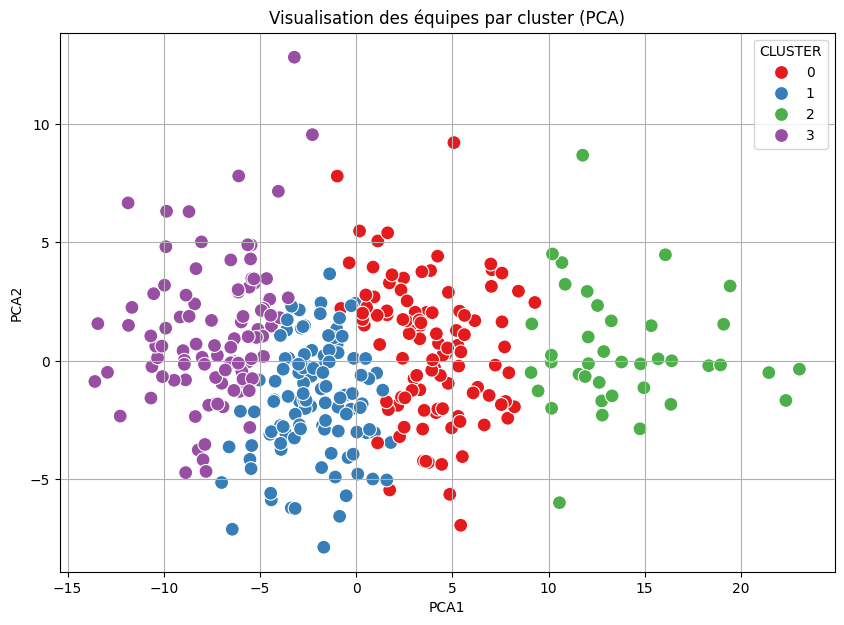

In [ ]:
# 10. Affichage
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# Réduire les dimensions pour visualiser
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Créer un DataFrame pour le graphe
pca_df = pd.DataFrame({
    "PCA1": X_pca[:, 0],
    "PCA2": X_pca[:, 1],
    "CLUSTER": clusters,
    "TEAM_NAME": teamAway_grouped.index
})

# Tracer les clusters
plt.figure(figsize=(10, 7))
sns.scatterplot(data=pca_df, x="PCA1", y="PCA2", hue="CLUSTER", palette="Set1", s=100)
#for i in range(pca_df.shape[0]):
#    plt.text(pca_df["PCA1"][i]+0.02, pca_df["PCA2"][i], pca_df["TEAM_NAME"][i], fontsize=9)
plt.title("Visualisation des équipes par cluster (PCA)")
plt.grid(True)
plt.show()


In [ ]:
# 11. Voir quelles équipes sont dans quel cluster
for c in sorted(teamAway_grouped["CLUSTER"].unique()):
    print(f"\nCluster {c} :")
    print(teamAway_grouped[teamAway_grouped["CLUSTER"] == c].index.tolist())


Cluster 0 :
['AZ', 'AaB', 'Accrington Stanley', 'Ajaccio', 'Antwerp', 'Arsenal de Sarandi', 'Athletico PR', 'Atlético Madrid', 'Atlético Tucumán', 'Barnsley', 'Beerschot-Wilrijk', 'Boca Juniors', 'Bolton Wanderers', 'Borussia Mönchengladbach', 'Bragantino', 'Brest', 'Brøndby', 'Burton Albion', 'Cambridge United', 'Cerezo Osaka', 'Charlton Athletic', 'Cheltenham Town', 'Colchester United', 'Consadole Sapporo', 'Corinthians', 'Coventry City', 'Cruzeiro', 'Defensa y Justicia', 'Doncaster Rovers', 'Eintracht Frankfurt', 'Exeter City', 'FC Utrecht', 'Fleetwood Town', 'Fluminense', 'Forest Green Rovers', 'Gamba Osaka', 'Grenoble Foot 38', 'Harrogate Town', 'Independiente', 'Internacional', 'Ipswich Town', 'Kashima Antlers', 'Kashiwa Reysol', 'LOSC Lille', 'Lanús', 'Lazio', 'Leicester City', 'Lens', 'Leyton Orient', 'Lincoln City', 'Lorient', 'Luton Town', 'Manchester United', 'Mansfield Town', 'Mechelen', 'Metz', 'Milan', 'Milton Keynes Dons', 'Monaco', 'Nagoya Grampus', "Newell's Old Boys"

# **Modèle de prédiction de résultat du match**

In [ ]:
# Fusionner les statistiques des équipes à domicile et à l'extérieur
data = teamHome_grouped.merge(teamAway_grouped, on='TEAM_NAME', suffixes=('_home', '_away'))

# Ajouter la colonne des clusters
data = data.merge(team_clusters, on='TEAM_NAME')
data['CLUSTER_home'] = data['CLUSTER']

# Ajouter la cible (résultat du match)
data['HOME_WINS'] = Ytrain['HOME_WINS']
data['DRAW'] = Ytrain['DRAW']
data['AWAY_WINS'] = Ytrain['AWAY_WINS']

In [ ]:
# Sélectionner les colonnes qui sont des features
features = data.drop(columns=["HOME_WINS", "DRAW", "AWAY_WINS", "TEAM_NAME", "CLUSTER", "CLUSTER_home"])

#Avec ce y on a une accuracy de 0.45 mais on a pensé que la matrice obtenue n'était pas correcte
# y = data["HOME_WINS"]

#Avec ce y on a une accuracy de 0.42
# Créer variable cible à 3 classes : -1 = AWAY_WIN, 0 = DRAW, 1 = HOME_WIN
y = data[["HOME_WINS", "DRAW", "AWAY_WINS"]].idxmax(axis=1).map({
    "AWAY_WINS": -1,
    "DRAW": 0,
    "HOME_WINS": 1
})

# Standardiser les features
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(features)  # Apprentissage des moyennes et écarts-types
X_scaled = scaler.fit_transform(features)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Diviser les données en train et test
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.3, random_state=42)

# Entraîner le modèle
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# Prédictions
y_pred = model.predict(X_test)

# Évaluation
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Infos classification :\n", classification_report(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

Accuracy: 0.41904761904761906
Infos classification :
               precision    recall  f1-score   support

          -1       0.28      0.41      0.33        22
           0       0.42      0.38      0.40        29
           1       0.51      0.44      0.48        54

    accuracy                           0.42       105
   macro avg       0.40      0.41      0.40       105
weighted avg       0.44      0.42      0.42       105

Confusion Matrix:
 [[ 9  2 11]
 [ 6 11 12]
 [17 13 24]]


**Rappel**
* **`precision `**: proportion de prédictions correctes parmi celles faites pour cette classe.
* **`recall `**: proportion des vrais cas bien retrouvés par le modèle.
* **`f1-score `**: moyenne harmonique entre precision et recall. Donne une vision globale.
* **`support `**: nombre d'exemples réels de cette classe dans les données de test.


* **`accuracy `**: proportion de bonnes prédictions globales : ici 42%.
* **`macro avg`**: moyenne simple des métriques pour chaque classe (donne le même poids à chaque classe).
* **`weighted avg`**: moyenne pondérée par le nombre d'exemples par classe (prend en compte les déséquilibres de classe).

commentaite: dans cette partieon doit plutöt utiliser les données test qui sont déjàprésentes dans le document de test


In [ ]:
label_mapping = {
    -1: "AWAY_WIN",
     0: "DRAW",
     1: "HOME_WIN"
}

y_test_named = y_test.map(label_mapping)
y_pred_named = pd.Series(y_pred).map(label_mapping)

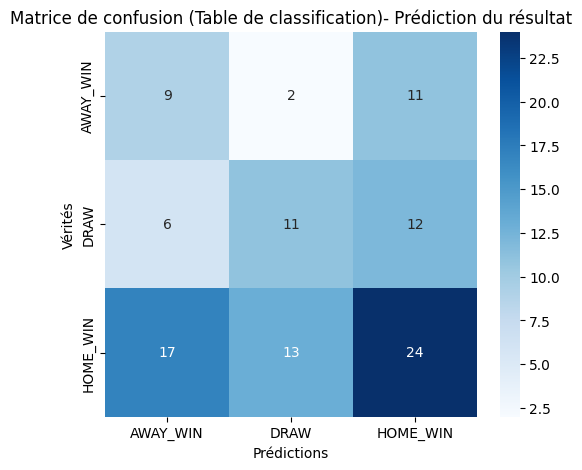

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

labels_named = ["AWAY_WIN", "DRAW", "HOME_WIN"]
cm = confusion_matrix(y_test_named, y_pred_named, labels=labels_named)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=labels_named, yticklabels=labels_named, cmap="Blues")
plt.xlabel("Prédictions")
plt.ylabel("Vérités")
plt.title("Matrice de confusion (Table de classification)- Prédiction du résultat")
plt.show()

In [ ]:
print(y_pred_named)

0      HOME_WIN
1      AWAY_WIN
2      AWAY_WIN
3          DRAW
4      HOME_WIN
         ...   
100    HOME_WIN
101        DRAW
102    HOME_WIN
103        DRAW
104    AWAY_WIN
Length: 105, dtype: object


In [ ]:
# === Génération du fichier CSV à soumettre ===

# Étape 1 : préparer X_test brut (non standardisé) pour récupérer les index
X_test_df = pd.DataFrame(X_test, columns=features.columns)  # pour correspondre aux colonnes
X_test_index = X_test_df.index  # pour récupérer les indices

# Étape 2 : reconstruire le format [HOME_WINS, DRAW, AWAY_WINS] à partir de y_pred
# y_pred contient 1 (HOME_WIN), 0 (DRAW) ou -1 (AWAY_WIN)

# Initialiser un DataFrame vide
submission_df = pd.DataFrame(0, index=range(len(y_pred)), columns=["HOME_WINS", "DRAW", "AWAY_WINS"])

# Remplir avec 1 à la bonne position
for i, pred in enumerate(y_pred):
    if pred == 1:
        submission_df.loc[i, "HOME_WINS"] = 1
    elif pred == 0:
        submission_df.loc[i, "DRAW"] = 1
    elif pred == -1:
        submission_df.loc[i, "AWAY_WINS"] = 1

# Ajouter la colonne ID
submission_df["ID"] = X_test_index.values
submission_df = submission_df[["ID", "HOME_WINS", "DRAW", "AWAY_WINS"]]

# Étape 3 : enregistrer en CSV
submission_df.to_csv("match_predictions.csv", index=False)
print("Fichier match_predictions.csv généré avec succès.")

from google.colab import files
files.download("match_predictions.csv")


Fichier match_predictions.csv généré avec succès.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Dans le code ci-dessous on essayait de faire la prédiction pour 2 équipes données

In [ ]:
# On suppose que les noms sont bien présents dans les données groupées
home_team = "Chelsea"
away_team = "Ajax"

# Récupérer les stats moyennes
home_stats = teamHome_grouped.loc[home_team]
away_stats = teamAway_grouped.loc[away_team]

# Ajouter les clusters
home_cluster = team_clusters[team_clusters["TEAM_NAME"] == home_team]["CLUSTER"].values[0]
away_cluster = team_clusters[team_clusters["TEAM_NAME"] == away_team]["CLUSTER"].values[0]


# Concaténer les données dans un seul DataFrame pour prédire
match_features = pd.concat([
    home_stats.add_prefix("H_"),
    pd.Series({"H_CLUSTER": home_cluster}),
    away_stats.add_prefix("A_"),
    pd.Series({"A_CLUSTER": away_cluster})
])


columns_used_in_training = features.columns.tolist()


# S’assurer que les colonnes sont dans le même ordre que X_train
match_scaled = scaler.transform([match_features[columns_used_in_training]])

# Prédiction
result = model.predict(match_scaled)[0]

print("Résultat prédit :", label_mapping[result])


KeyError: "None of [Index(['TEAM_SHOTS_TOTAL_season_sum_home',\n       'TEAM_SHOTS_INSIDEBOX_season_sum_home',\n       'TEAM_SHOTS_OFF_TARGET_season_sum_home',\n       'TEAM_SHOTS_ON_TARGET_season_sum_home',\n       'TEAM_SHOTS_OUTSIDEBOX_season_sum_home', 'TEAM_PASSES_season_sum_home',\n       'TEAM_SUCCESSFUL_PASSES_season_sum_home', 'TEAM_SAVES_season_sum_home',\n       'TEAM_CORNERS_season_sum_home', 'TEAM_FOULS_season_sum_home',\n       ...\n       'TEAM_REDCARDS_5_last_match_std_away',\n       'TEAM_OFFSIDES_5_last_match_std_away',\n       'TEAM_ATTACKS_5_last_match_std_away',\n       'TEAM_PENALTIES_5_last_match_std_away',\n       'TEAM_SUBSTITUTIONS_5_last_match_std_away',\n       'TEAM_BALL_SAFE_5_last_match_std_away',\n       'TEAM_DANGEROUS_ATTACKS_5_last_match_std_away',\n       'TEAM_INJURIES_5_last_match_std_away',\n       'TEAM_GOALS_5_last_match_std_away', 'CLUSTER_away'],\n      dtype='object', length=281)] are in the [index]"